# Run the FGCM step 2a by hand : `fgcmBuildFromIsolatedStar` -> `fgcmFitCycle` -> `fgcmOutputProducts`

- author : Sylvie Dagoret-Campagne
- creation date : 2026-11-12
- last update 2026-11-13
- purpose : replay the three tasks of `DRP.yaml#step2a-recalibrate-global` from the stage1 collection of the COSMOS run, look at what they read and what they write, and compare with the stage2 collection already produced by bps (`stage2_v2`)
- final goal : inject the atmospheric parameters measured by AuxTel (libRadtran) instead of fitting them, and fit only the instrumental effects. This needs (1) a new `fgcmLookUpTable` computed with libRadtran, (2) control of what `fgcmFitCycle` is allowed to fit

## Contents

1. Configuration
2. The three tasks in the pipeline : connections and configuration
3. Inputs : what is read, and where it comes from
4. The `fgcmLookUpTable`
5. Run the three tasks (`pipetask qgraph` + `pipetask run`)
6. Outputs : what is written
7. `fgcmVisitCatalog` and star observations : the cuts of `fgcmFitCycle`
8. Fit parameters and zeropoints
9. Comparison with the bps run (`stage2_v2`)
10. Next steps : injecting the atmosphere

Run it with the same release as the bps jobs (`w_2026_43`) : a different release may give different numerics (see `README.md`).

## 1. Configuration

In [1]:
import os
import re
import shlex
import shutil
import subprocess
import logging
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from lsst.daf.butler import Butler
from lsst.pipe.base import Pipeline
import lsst.fgcmcal

logging.basicConfig(level=logging.WARNING, format='%(name)s %(levelname)s: %(message)s', force=True)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 200)

print('python        :', platform.python_version())
print('numpy         :', np.__version__)
print('fgcmcal from  :', lsst.fgcmcal.__file__)
print('DRP_PIPE_DIR  :', os.getenv('DRP_PIPE_DIR'))

python        : 3.13.18
numpy         : 2.4.6
fgcmcal from  : /pbs/home/d/dagoret/rubin_user/REPO/fgcmcal/python/lsst/fgcmcal/__init__.py
DRP_PIPE_DIR  : /cvmfs/sw.lsst.eu/almalinux-x86_64/lsst_distrib/w_2026_46/conda/envs/lsst-scipipe-14.0.0-exact/share/eups/Linux64/drp_pipe/g7715199d20+993d0b9996


In [2]:
!eups list -s | grep LOCAL

eups                  LOCAL:/cvmfs/sw.lsst.eu/almalinux-x86_64/lsst_distrib/w_2026_46/conda/envs/lsst-scipipe-14.0.0-exact/eups 	setup
fgcmcal               LOCAL:/pbs/home/d/dagoret/rubin_user/REPO/fgcmcal 	setup


In [3]:
username = os.getenv('USER')

# ---- collections -------------------------------------------------------------------------------
#RUN_NAME = 'runcosmos01_20261103_tract9813patchsel_RunCosmos9patches'
RUN_NAME = 'runelaiss1_20261111_tract2877patchsel_mediumpatcharray'
STAGE1 = f'u/{username}/LSSTCam/{RUN_NAME}/stage1/20261111T170346Z'          # input of the stage 2
STAGE2_REF = f'u/{username}/LSSTCam/{RUN_NAME}/stage2_v2'   # outputs of the bps run (reference)
DEFAULTS = 'LSSTCam/defaults'
# New look-up table (see make_fgcm_lut_obsatmo.sh) : chained BEFORE the defaults. None = the default LUT
LUT_COLLECTION = None    # e.g. f'u/{username}/LSSTCam/fgcm_lut_obsatmo01'
INPUT_COLLECTIONS = ([LUT_COLLECTION] if LUT_COLLECTION else []) + [STAGE1, DEFAULTS]

# Chained collection written by THIS notebook (each execution creates a new timestamped run inside)
OUT_COLLECTION = f'u/{username}/LSSTCam/{RUN_NAME}/fgcm_nb01' + ('_newlut' if LUT_COLLECTION else '')

# ---- pipeline ----------------------------------------------------------------------------------
PIPELINE_URI = '${DRP_PIPE_DIR}/pipelines/LSSTCam/DRP.yaml#step2a-recalibrate-global'
TASK_LABELS = ['fgcmBuildFromIsolatedStar', 'fgcmFitCycle', 'fgcmOutputProducts']

# Same change as in the bps yaml of stage2_v2 (extraQgraphOptions: "-c fgcmFitCycle:minStarPerExp=100")
CONFIG_OVERRIDES = {
    'fgcmFitCycle': {'minStarPerExp': 100},
}

# ---- OPTIONAL DIAGNOSTIC TEST (superstar hypothesis) ---------------------------------------------
# fgcmFitCycle stops because every exposure of the u and i bands is cut by the gray cuts (gray offsets of
# -1.5 to +1 mag per (band, epoch)). Hypothesis : the superstar flat precomputed on the initial cycle is
# polluted by CCDs with <= 2 observations, which carry the sentinel value -9999 in the mean / std.
# Set FGCM_TEST to one of the keys of TESTS :
#   None           : baseline, same configuration as the bps stage2_v2 run (default)
#   'noprecompute' : do not precompute the superstar flat on the initial cycle
#   'oneepoch'     : a single epoch instead of epochMjds = [0, 60859, 60949, 100000]
# A test writes in its own collection (suffix _<FGCM_TEST>) and its own data_ / figs_ folders :
# the baseline results are not overwritten. To compare, look at the gray percentiles per band in
# data_<NB_TAG>/pipetask_run.log and at data_<NB_TAG>/fgcm_exposure_diagnostics_cycle0.csv
FGCM_TEST = 'oneepoch'
TESTS = {
    None: {},
    'noprecompute': {'precomputeSuperStarInitialCycle': False},
    'oneepoch': {'epochMjds': [0.0, 100000.0]},
}
CONFIG_OVERRIDES['fgcmFitCycle'].update(TESTS[FGCM_TEST])
OUT_COLLECTION = OUT_COLLECTION + (f'_{FGCM_TEST}' if FGCM_TEST else '')
print('FGCM_TEST    :', FGCM_TEST, TESTS[FGCM_TEST])

# ---- selection : the same files as in the bps shell scripts --------------------------------------
# Folder of the bps run : tractIds.txt, patchIds.txt, ccdIds.txt, visits_to_exclude.txt, check_fgcm_fit_cycle.py
RUN_DIR = Path('../../scripts/myRunDRPELAISS1/2026-11-11-DRPstages1and2inTractandSelectedPatches')

# Data query of the qgraph : 'minimal' = instrument, skymap, tract, excluded visits ; 'bps' = the one of the bps scripts
# (adds patch, detector, science). The three tasks have dimensions {instrument} : with 'bps' the registry has to join
# visit x detector x patch overlaps, which exceeded the temp_file_limit of the postgres server at CC-IN2P3.
QUERY_MODE = 'minimal'
QGRAPH_EXTRA_OPTIONS = []    # e.g. ['--dataset-query-constraint', 'preliminary_visit_summary'] if still too heavy

# ---- switches ----------------------------------------------------------------------------------
EXECUTE = True                      # False : only print the commands. True : run qgraph + run
INSPECT = 'reference'                # 'reference' : look at STAGE2_REF, 'new' : look at OUT_COLLECTION
INSPECT_COLLECTION = STAGE2_REF if INSPECT == 'reference' else OUT_COLLECTION

# ---- output directories (same conventions as the other notebooks) -------------------------------
NB_TAG = '01_DDFELAISS1_runfgcmFitCycle' + (f'_{FGCM_TEST}' if FGCM_TEST else '')
DATA_DIR = Path(f'data_{NB_TAG}')
FIG_DIR = Path(f'figs_{NB_TAG}')
DATA_DIR.mkdir(exist_ok=True)
os.environ['FGCMCAL_DIAG_DIR'] = str(DATA_DIR)   # per-exposure diagnostics of the forked fgcmFitCycle go there
FIG_DIR.mkdir(exist_ok=True)

print('stage1       :', STAGE1)
print('reference    :', STAGE2_REF)
print('new output   :', OUT_COLLECTION)
print('inspecting   :', INSPECT_COLLECTION)

FGCM_TEST    : oneepoch {'epochMjds': [0.0, 100000.0]}
stage1       : u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage1/20261111T170346Z
reference    : u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage2_v2
new output   : u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/fgcm_nb01_oneepoch
inspecting   : u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage2_v2


In [4]:
butler = Butler('main')
instrument = 'LSSTCam'


def save_fig(fig, name):
    '''Save a figure as PNG and PDF in FIG_DIR.'''
    for ext in ('png', 'pdf'):
        fig.savefig(FIG_DIR / f'{name}.{ext}', bbox_inches='tight')


def read_list(filename):
    '''Values of a text file (one per line, or comma separated); [] if the file does not exist.'''
    path = RUN_DIR / filename
    if not path.exists():
        print(f'   {path} not found')
        return []
    return [v for v in re.split(r'[,\s]+', path.read_text().strip()) if v]


def query_refs(dataset_type, collections, find_first=True):
    '''Dataset references of a type. Falls back to findFirst=False (e.g. calibration collections).'''
    if isinstance(collections, str):
        collections = [collections]
    try:
        return list(butler.registry.queryDatasets(dataset_type, collections=collections, findFirst=find_first))
    except Exception as exc:
        if find_first:
            return query_refs(dataset_type, collections, find_first=False)
        print(f'   {dataset_type}: query failed ({type(exc).__name__}: {str(exc)[:150]})')
        return []


def summarize(obj, nmax=80):
    '''Short description of a catalog-like object (afw catalog, astropy / arrow table, DataFrame, dict).'''
    print('type :', type(obj))
    if hasattr(obj, 'schema') and hasattr(obj.schema, 'getNames'):
        names = list(obj.schema.getNames())
        print(f'rows : {len(obj)} ; fields : {len(names)}')
        print(names[:nmax])
    elif hasattr(obj, 'colnames'):
        print(f'rows : {len(obj)} ; columns : {len(obj.colnames)}')
        print(list(obj.colnames)[:nmax])
    elif isinstance(obj, pd.DataFrame):
        print(f'rows : {len(obj)} ; columns : {len(obj.columns)}')
        print(list(obj.columns)[:nmax])
    elif isinstance(obj, dict):
        print('keys :', list(obj.keys())[:nmax])
    else:
        print(repr(obj)[:500])

In [5]:
# Selection of the stage2 bps run (tract, patches, detectors, excluded visits)
tract_ids = read_list('tractIds.txt')
patch_ids = read_list('patchIds_mediumarray.txt')
ccd_ids = read_list('ccdIds.txt')
no_visits = read_list('visits_to_exclude.txt')

print('tracts   :', tract_ids)
print('patches  :', patch_ids)
print('detectors:', len(ccd_ids))
print('visits excluded :', no_visits)

parts = [f"instrument='{instrument}'", "skymap='lsst_cells_v2'"]
if tract_ids:
    parts.append(f"tract IN ({','.join(tract_ids)})")
if patch_ids and QUERY_MODE == 'bps':
    parts.append(f"patch IN ({','.join(patch_ids)})")
if ccd_ids and QUERY_MODE == 'bps':
    parts.append(f"detector IN ({','.join(ccd_ids)})")
if no_visits:
    parts.append(f"{'exposure' if QUERY_MODE == 'bps' else 'visit'} NOT IN ({','.join(no_visits)})")
if QUERY_MODE == 'bps':
    parts.append("exposure.observation_type='science'")
DATA_QUERY = ' AND '.join(parts)
print()
print('dataQuery :', DATA_QUERY)

tracts   : ['2877']
patches  : ['26', '27', '28', '29', '36', '37', '38', '39', '46', '47', '48', '49', '56', '57', '58', '59', '66', '67', '68', '69']
detectors: 179
visits excluded : ['2025090600517', '2025102400260', '2025111400078', '2025111400079', '2025111400090', '2025111800147', '2025112100040', '2025112100152', '2025062900657', '2025071200593', '2025071200594', '2025071200595', '2025071200596', '2025071200599', '2025071200600', '2025072200264', '2025072300590', '2025072800378', '2025082600458', '2025082600459', '2025082600460', '2025082600461', '2025082600462', '2025082800150', '2025082800151', '2025082800152', '2025082800153', '2025082800154', '2025082800155', '2025092100071', '2025111600349', '2025111600350', '2025111600351', '2025120100056', '2025120100057', '2026011800097', '2026011800098', '2026011800099', '2026011800100', '2026011800112', '2026011800113', '2026011800114', '2026011800115', '2026011800116', '2026011800119', '2026011800120']

dataQuery : instrument='LSSTCam

Check that `visits_to_exclude.txt` is the same list as the `NOVISITS` used by the `stage2_v2` run (`README.md` : first the bad visit `2026040400105`, then the visits without PSF). If not, edit `no_visits` above.

## 2. The three tasks in the pipeline : connections and configuration

The pipeline is read exactly as in the bps job (`DRP.yaml#step2a-recalibrate-global`) and the configuration overrides are applied with `Pipeline.addConfigOverride`. The connections tell which dataset types each task reads and writes : this is the list of inputs to investigate, and of outputs to display.

Note that `fgcmLookUpTable` is read by the three tasks : changing it invalidates the three of them, which is why they are replayed together.

In [6]:
pipeline_uri = os.path.expandvars(PIPELINE_URI)
pipeline = Pipeline.from_uri(pipeline_uri)
for label, overrides in CONFIG_OVERRIDES.items():
    for key, value in overrides.items():
        pipeline.addConfigOverride(label, key, value)

graph = pipeline.to_graph()
try:
    graph.resolve(butler.registry)
except Exception as exc:
    print(f'graph not resolved (dimensions / storage classes may be missing) : {type(exc).__name__}: {str(exc)[:150]}')

print('pipeline :', pipeline_uri)
for label in TASK_LABELS:
    print(f'  {label:28s}', graph.tasks[label].task_class_name)

pipeline : /cvmfs/sw.lsst.eu/almalinux-x86_64/lsst_distrib/w_2026_46/conda/envs/lsst-scipipe-14.0.0-exact/share/eups/Linux64/drp_pipe/g7715199d20+993d0b9996/pipelines/LSSTCam/DRP.yaml#step2a-recalibrate-global
  fgcmBuildFromIsolatedStar    lsst.fgcmcal.fgcmBuildFromIsolatedStars.FgcmBuildFromIsolatedStarsTask
  fgcmFitCycle                 lsst.fgcmcal.fgcmFitCycle.FgcmFitCycleTask
  fgcmOutputProducts           lsst.fgcmcal.fgcmOutputProducts.FgcmOutputProductsTask


In [7]:
def connection_table(graph, label):
    '''One row per connection of a task : kind, connection name, dataset type, dimensions, storage class.'''
    node = graph.tasks[label]
    groups = [
        ('init input', getattr(node.init, 'inputs', {})),
        ('input', getattr(node, 'inputs', {})),
        ('prerequisite', getattr(node, 'prerequisite_inputs', {})),
        ('init output', getattr(node.init, 'outputs', {})),
        ('output', getattr(node, 'outputs', {})),
    ]
    rows = []
    for kind, edges in groups:
        for conn, edge in edges.items():
            name = getattr(edge, 'parent_dataset_type_name', None) or edge.dataset_type_name
            dims, storage = '', ''
            try:
                dtn = graph.dataset_types[name]
                dims = ', '.join(dtn.dimensions.names)
                storage = dtn.storage_class_name
            except Exception:
                pass
            rows.append(dict(task=label, kind=kind, connection=conn, datasetType=name,
                             dimensions=dims, storageClass=storage))
    return pd.DataFrame(rows)


connections = pd.concat([connection_table(graph, label) for label in TASK_LABELS], ignore_index=True)
for label in TASK_LABELS:
    print(f'===== {label}')
    with pd.option_context('display.max_colwidth', None):
        display(connections[connections.task == label].drop(columns='task').reset_index(drop=True))

===== fgcmBuildFromIsolatedStar


,kind,connection,datasetType,dimensions,storageClass
0,input,visit_summaries,preliminary_visit_summary,"band, instrument, day_obs, physical_filter, visit",ExposureCatalog
1,input,isolated_star_cats,isolated_star_association,"instrument, skymap, tract",ArrowAstropy
2,input,isolated_star_sources,isolated_star,"instrument, skymap, tract",ArrowAstropy
3,prerequisite,fgcm_lookup_table,fgcmLookUpTable,instrument,Catalog
4,prerequisite,camera,camera,instrument,Camera
5,prerequisite,ref_cat,the_monster_20250219,htm7,SimpleCatalog
6,output,fgcm_reference_stars,fgcm_reference_stars,instrument,ArrowAstropy
7,output,fgcm_star_ids,fgcm_star_ids,instrument,ArrowAstropy
8,output,fgcm_star_observations,fgcm_star_observations,instrument,ArrowAstropy
9,output,fgcm_visit_catalog,fgcmVisitCatalog,instrument,Catalog


===== fgcmFitCycle


,kind,connection,datasetType,dimensions,storageClass
0,input,fgcmStarObservationsParquet,fgcm_star_observations,instrument,ArrowAstropy
1,input,fgcmStarIdsParquet,fgcm_star_ids,instrument,ArrowAstropy
2,input,fgcmVisitCatalog,fgcmVisitCatalog,instrument,Catalog
3,input,fgcmReferenceStarsParquet,fgcm_reference_stars,instrument,ArrowAstropy
4,prerequisite,camera,camera,instrument,Camera
5,prerequisite,fgcmLookUpTable,fgcmLookUpTable,instrument,Catalog
6,output,fgcm_Cycle4_FlaggedStars,fgcm_Cycle4_FlaggedStars,instrument,Catalog
7,output,fgcm_Cycle4_ExpgrayInitial_Plot,fgcm_Cycle4_ExpgrayInitial_Plot,"band, instrument",Plot
8,output,fgcm_Cycle4_ExpgrayUT_Plot,fgcm_Cycle4_ExpgrayUT_Plot,"band, instrument",Plot
9,output,fgcm_Cycle5_ExpgrayAirmass_Plot,fgcm_Cycle5_ExpgrayAirmass_Plot,"band, instrument",Plot


===== fgcmOutputProducts


,kind,connection,datasetType,dimensions,storageClass
0,input,skymap,skyMap,skymap,SkyMap
1,input,fgcmVisitCatalog,fgcmVisitCatalog,instrument,Catalog
2,input,fgcmStandardStars,fgcm_Cycle5_StandardStars,instrument,SimpleCatalog
3,input,fgcmAtmosphereParameters,fgcm_Cycle5_AtmosphereParameters,instrument,Catalog
4,input,fgcmZeropoints,fgcm_Cycle5_Zeropoints,instrument,Catalog
5,prerequisite,camera,camera,instrument,Camera
6,prerequisite,fgcmLookUpTable,fgcmLookUpTable,instrument,Catalog
7,output,fgcmTransmissionAtmosphere,transmission_atmosphere_fgcm,"band, instrument, day_obs, physical_filter, visit",TransmissionCurve
8,output,fgcmTractStars,fgcm_standard_star,"instrument, skymap, tract",ArrowAstropy
9,output,fgcmPhotoCalib,fgcmPhotoCalibCatalog,"band, instrument, day_obs, physical_filter, visit",ExposureCatalog


In [8]:
# Datasets read by the three tasks but not written by them = what must exist in the input collections
SKIP_SUFFIXES = ('_log', '_metadata', '_config')
produced = set(connections.loc[connections.kind.isin(['output', 'init output']), 'datasetType'])
read = set(connections.loc[connections.kind.isin(['input', 'prerequisite', 'init input']), 'datasetType'])

external_inputs = sorted(read - produced)
output_names = sorted(n for n in produced if not n.endswith(SKIP_SUFFIXES))

print('external inputs :', external_inputs)
print('outputs         :', output_names)

external inputs : ['camera', 'fgcmLookUpTable', 'isolated_star', 'isolated_star_association', 'preliminary_visit_summary', 'skyMap', 'the_monster_20250219']
outputs         : ['fgcmPhotoCalibCatalog', 'fgcmVisitCatalog', 'fgcm_Cycle0_FitParameters', 'fgcm_Cycle0_FlaggedStars', 'fgcm_Cycle0_OutputConfig', 'fgcm_Cycle1_FitParameters', 'fgcm_Cycle1_FlaggedStars', 'fgcm_Cycle1_OutputConfig', 'fgcm_Cycle2_FitParameters', 'fgcm_Cycle2_FlaggedStars', 'fgcm_Cycle2_OutputConfig', 'fgcm_Cycle3_FitParameters', 'fgcm_Cycle3_FlaggedStars', 'fgcm_Cycle3_OutputConfig', 'fgcm_Cycle4_AbsThroughputs_Plot', 'fgcm_Cycle4_Apercorr_Plot', 'fgcm_Cycle4_CcdChromaticity_Plot', 'fgcm_Cycle4_ChisqFit_Plot', 'fgcm_Cycle4_CompareRedblueExpgray_Plot', 'fgcm_Cycle4_CompareRedblueMirrorchrom_Plot', 'fgcm_Cycle4_DensityAllStarMap_Plot', 'fgcm_Cycle4_DensityGoodStarMap_Plot', 'fgcm_Cycle4_EpsilonDetectorMatchscale_Plot', 'fgcm_Cycle4_EpsilonDetector_Plot', 'fgcm_Cycle4_EpsilonGlobal_Plot', 'fgcm_Cycle4_EpsilonMap_Plot'

In [9]:
# Effective configuration of the three tasks (after the overrides) : a few fields, and the full dump in DATA_DIR
FIELDS = {
    'fgcmBuildFromIsolatedStar': ['doApplyWcsJacobian', 'bands', 'requiredBands', 'physicalFilterMap',
                                  'doReferenceMatches', 'minPerBand'],
    'fgcmFitCycle': ['doMultipleCycles', 'cycleNumber', 'isFinalCycle', 'multipleCyclesFinalCycleNumber',
                     'useParquetCatalogFormat', 'bands', 'fitBands', 'freezeStdAtmosphere',
                     'doReferenceCalibration', 'minStarPerExp', 'minExpPerNight', 'expGrayInitialCut',
                     'expFwhmCutDict', 'expGrayPhotometricCutDict', 'expVarGrayPhotometricCutDict',
                     'instrumentParsPerBand', 'nCore'],
    'fgcmOutputProducts': ['doComposeWcsJacobian', 'doReferenceCalibration', 'doApplyMirrorChromaticity'],
}

for label in TASK_LABELS:
    config = graph.tasks[label].config
    (DATA_DIR / f'config_{label}.py').write_text(config.saveToString())
    print(f'===== {label}')
    for name in FIELDS[label]:
        value = getattr(config, name, 'n/a')
        print(f'   {name:34s}', dict(value) if hasattr(value, 'items') else value)
print()
print(f'full configurations written in {DATA_DIR}/config_<task>.py')

===== fgcmBuildFromIsolatedStar
   doApplyWcsJacobian                 True
   bands                              n/a
   requiredBands                      []
   physicalFilterMap                  {'u_24': 'u', 'g_6': 'g', 'r_57': 'r', 'i_39': 'i', 'z_20': 'z', 'y_10': 'y'}
   doReferenceMatches                 True
   minPerBand                         2
===== fgcmFitCycle
   doMultipleCycles                   True
   cycleNumber                        0
   isFinalCycle                       False
   multipleCyclesFinalCycleNumber     5
   useParquetCatalogFormat            True
   bands                              ['u', 'g', 'r', 'i', 'z', 'y']
   fitBands                           ['u', 'g', 'r', 'i', 'z', 'y']
   freezeStdAtmosphere                True
   doReferenceCalibration             True
   minStarPerExp                      100
   minExpPerNight                     3
   expGrayInitialCut                  -0.25
   expFwhmCutDict                     {'u': 2.0, 'g': 2.0, 'r': 

## 3. Inputs : what is read, and where it comes from

For each external input : number of datasets found in `[stage1, LSSTCam/defaults]` and the run (or calibration collection) holding the first one. Calibration datasets (e.g. `fgcmLookUpTable`, `camera`) have a validity range and are listed without `findFirst`.

In [10]:
rows = []
for name in external_inputs:
    refs = query_refs(name, INPUT_COLLECTIONS)
    rows.append(dict(datasetType=name, n=len(refs), first_run=refs[0].run if refs else '',
                     dimensions=', '.join(refs[0].datasetType.dimensions.names) if refs else '',
                     storageClass=refs[0].datasetType.storageClass_name if refs else ''))
inputs_table = pd.DataFrame(rows).set_index('datasetType')
with pd.option_context('display.max_colwidth', None):
    display(inputs_table)

,n,first_run,dimensions,storageClass
datasetType,,,,
camera,1,LSSTCam/calib/DM-51669/unbounded,instrument,Camera
fgcmLookUpTable,1,LSSTCam/calib/fgcmcal/DM-50154,instrument,Catalog
isolated_star,1,u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage1/20261111T170346Z,"instrument, skymap, tract",ArrowAstropy
isolated_star_association,1,u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage1/20261111T170346Z,"instrument, skymap, tract",ArrowAstropy
preliminary_visit_summary,1147,u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage1/20261111T170346Z,"band, instrument, day_obs, physical_filter, visit",ExposureCatalog
skyMap,2,skymaps,skymap,SkyMap
the_monster_20250219,131072,refcats/DM-49042/the_monster_20250219,htm7,SimpleCatalog


Reference catalogs (used by `fgcmBuildFromIsolatedStar` for the absolute calibration) are prerequisite inputs found per region : they may not show up above with a simple query. Look at the quantum graph built in section 5 to see which ones are really used.

## 4. The `fgcmLookUpTable`

The look-up table gives, for each band, the flux integral as a function of the atmosphere parameters (pressure, PWV, O3, aerosol tau and alpha, zenith distance) and the instrument throughput. According to the `lsst/fgcmcal` README, FGCM needs **MODTRAN4** to generate new atmosphere tables, and the atmosphere tables for Cerro Pachon are shipped with the package. The standard atmosphere of the LSST table is therefore a MODTRAN4 one : to use libRadtran, the atmosphere table (and then this look-up table, made by `FgcmMakeLutTask`) must be recomputed by hand.

In [11]:
lut_refs = query_refs('fgcmLookUpTable', INPUT_COLLECTIONS, find_first=False)
print(f'{len(lut_refs)} fgcmLookUpTable dataset(s) in {INPUT_COLLECTIONS}')
for ref in lut_refs[:10]:
    print('  ', ref.run, '|', ref.dataId)

if lut_refs:
    lut = butler.get(lut_refs[0])
    summarize(lut)

1 fgcmLookUpTable dataset(s) in ['u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage1/20261111T170346Z', 'LSSTCam/defaults']
   LSSTCam/calib/fgcmcal/DM-50154 | {instrument: 'LSSTCam'}
type : <class 'lsst.afw.table.BaseCatalog'>
rows : 14 ; fields : 33
['lambdaStep', 'i10Std', 'atmLambda', 'i2Std', 'o3', 'lambdaRange', 'lambdaB', 'pmbFactor', 'tau', 'tablename', 'zenith', 'lut', 'pmbStd', 'nCcd', 'lambdaStd', 'lambdaNorm', 'pmb', 'elevation', 'i0Std', 'o3Std', 'pwv', 'physicalFilters', 'alphaStd', 'i1Std', 'pwvStd', 'stdPhysicalFilters', 'tauStd', 'lambdaStdFilter', 'pmbElevation', 'atmStdTrans', 'luttype', 'alpha', 'zenithStd']


In [12]:
# Configuration used to BUILD the look-up table, if the task config was saved in the repository
for cfg_name in ('fgcmMakeLut_config', 'fgcmMakeLut'):
    refs = query_refs(cfg_name, INPUT_COLLECTIONS + ['LSSTCam/calib', 'LSSTCam/runs'], find_first=False)
    if refs:
        print('found', cfg_name, 'in', refs[0].run)
        build_config = butler.get(refs[0])
        for key, value in build_config.toDict().items():
            if any(s in key.lower() for s in ('atmos', 'pmb', 'pwv', 'o3', 'tau', 'alpha', 'zenith', 'filter')):
                print(f'   {key:30s}', value)
        break
else:
    print('The config of the task that built the look-up table is not in the searched collections.')
    print('Default configuration of FgcmMakeLutTask :')
    from lsst.fgcmcal import FgcmMakeLutConfig
    for key, value in FgcmMakeLutConfig().toDict().items():
        if any(s in key.lower() for s in ('atmos', 'pmb', 'pwv', 'o3', 'tau', 'alpha', 'zenith')):
            print(f'   {key:30s}', value)

The config of the task that built the look-up table is not in the searched collections.
Default configuration of FgcmMakeLutTask :
   atmosphereTableName            None


## 5. Run the three tasks

`pipetask qgraph` builds the quantum graph (this is where the dataQuery and the inputs are checked), then `pipetask run` executes it with the outputs in a new run of `OUT_COLLECTION`. With `EXECUTE = False` the commands are only printed : copy them in a terminal (same environment) if you prefer to run them there.

`fgcmFitCycle` is the heavy one (it loads all the star observations in memory and uses `nCore` cores) : at CC-IN2P3 use an interactive session with enough memory.

In [13]:
qgraph_file = DATA_DIR / 'step2a.qgraph'
config_opts = []
for label, overrides in CONFIG_OVERRIDES.items():
    for key, value in overrides.items():
        config_opts += ['-c', f'{label}:{key}={value}']

cmd_qgraph = ['pipetask', 'qgraph', '-b', 'main', '-i', ','.join(INPUT_COLLECTIONS), '-o', OUT_COLLECTION,
              '-p', pipeline_uri, '-d', DATA_QUERY, *config_opts, *QGRAPH_EXTRA_OPTIONS, '--save-qgraph', str(qgraph_file)]
cmd_run = ['pipetask', 'run', '-b', 'main', '-g', str(qgraph_file), '--register-dataset-types', '-j', '1']

print(shlex.join(cmd_qgraph))
print()
print(shlex.join(cmd_run))

pipetask qgraph -b main -i u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage1/20261111T170346Z,LSSTCam/defaults -o u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/fgcm_nb01_oneepoch -p '/cvmfs/sw.lsst.eu/almalinux-x86_64/lsst_distrib/w_2026_46/conda/envs/lsst-scipipe-14.0.0-exact/share/eups/Linux64/drp_pipe/g7715199d20+993d0b9996/pipelines/LSSTCam/DRP.yaml#step2a-recalibrate-global' -d 'instrument='"'"'LSSTCam'"'"' AND skymap='"'"'lsst_cells_v2'"'"' AND tract IN (2877) AND visit NOT IN (2025090600517,2025102400260,2025111400078,2025111400079,2025111400090,2025111800147,2025112100040,2025112100152,2025062900657,2025071200593,2025071200594,2025071200595,2025071200596,2025071200599,2025071200600,2025072200264,2025072300590,2025072800378,2025082600458,2025082600459,2025082600460,2025082600461,2025082600462,2025082800150,2025082800151,2025082800152,2025082800153,2025082800154,2025082800155,2025092100071,2025111600349,2025111600350,202511

In [14]:
def run_cmd(cmd, log_path):
    '''Run a command, write the full log in log_path and print only the lines that matter.'''
    if shutil.which(cmd[0]) is None:
        raise RuntimeError(f'{cmd[0]} not found in PATH : is the lsst environment set up for this kernel ?')
    print('$', shlex.join(cmd))
    keep = ('ERROR', 'FATAL', 'Traceback', 'Error', 'quanta', 'Quantum', 'graph')
    with open(log_path, 'w') as log:
        proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in proc.stdout:
            log.write(line)
            if any(word in line for word in keep):
                print(line.rstrip()[:300])
        returncode = proc.wait()
    print(f'return code : {returncode} ; full log : {log_path}')
    if returncode != 0:
        raise RuntimeError(f'{cmd[1]} failed, see {log_path}')


if EXECUTE:
    run_cmd(cmd_qgraph, DATA_DIR / 'pipetask_qgraph.log')
    run_cmd(cmd_run, DATA_DIR / 'pipetask_run.log')
    butler = Butler('main')    # fresh butler : sees the new collections
else:
    print('EXECUTE = False : nothing run. Inspecting', INSPECT_COLLECTION)

$ pipetask qgraph -b main -i u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage1/20261111T170346Z,LSSTCam/defaults -o u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/fgcm_nb01_oneepoch -p '/cvmfs/sw.lsst.eu/almalinux-x86_64/lsst_distrib/w_2026_46/conda/envs/lsst-scipipe-14.0.0-exact/share/eups/Linux64/drp_pipe/g7715199d20+993d0b9996/pipelines/LSSTCam/DRP.yaml#step2a-recalibrate-global' -d 'instrument='"'"'LSSTCam'"'"' AND skymap='"'"'lsst_cells_v2'"'"' AND tract IN (2877) AND visit NOT IN (2025090600517,2025102400260,2025111400078,2025111400079,2025111400090,2025111800147,2025112100040,2025112100152,2025062900657,2025071200593,2025071200594,2025071200595,2025071200596,2025071200599,2025071200600,2025072200264,2025072300590,2025072800378,2025082600458,2025082600459,2025082600460,2025082600461,2025082600462,2025082800150,2025082800151,2025082800152,2025082800153,2025082800154,2025082800155,2025092100071,2025111600349,2025111600350,2025

If `fgcmFitCycle` stops with `FATAL: All observations in %s band have been cut!`, see `check_fgcm_fit_cycle.py` and section 7 : the cut is on the number of observations per visit (`minStarPerExp`), and the message does not say which band.

## 6. Outputs : what is written

Number of datasets of each output type of the three tasks in `INSPECT_COLLECTION`.

In [15]:
print('collection :', INSPECT_COLLECTION)
rows = []
for name in output_names:
    refs = query_refs(name, INSPECT_COLLECTION, find_first=False)
    rows.append(dict(datasetType=name, n=len(refs),
                     dimensions=', '.join(refs[0].datasetType.dimensions.names) if refs else '',
                     storageClass=refs[0].datasetType.storageClass_name if refs else '',
                     run=refs[0].run if refs else ''))
outputs_table = pd.DataFrame(rows).set_index('datasetType')
with pd.option_context('display.max_colwidth', None):
    display(outputs_table)

collection : u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage2_v2


,n,dimensions,storageClass,run
datasetType,,,,
fgcmPhotoCalibCatalog,0,,,
fgcmVisitCatalog,1,instrument,Catalog,u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage2_v2/20261112T110933Z
fgcm_Cycle0_FitParameters,0,,,
fgcm_Cycle0_FlaggedStars,0,,,
fgcm_Cycle0_OutputConfig,0,,,
fgcm_Cycle1_FitParameters,0,,,
fgcm_Cycle1_FlaggedStars,0,,,
fgcm_Cycle1_OutputConfig,0,,,
fgcm_Cycle2_FitParameters,0,,,


## 7. `fgcmVisitCatalog` and star observations : the cuts of `fgcmFitCycle`

Same analysis as `check_fgcm_fit_cycle.py` : one row per visit, number of star observations per visit, and the visits flagged by the cuts that only need these inputs (`BAD_FWHM`, `NO_STARS`, `TOO_FEW_STARS`).

In [16]:
visit_ref = (query_refs('fgcmVisitCatalog', INSPECT_COLLECTION) or [None])[0]
obs_ref = (query_refs('fgcm_star_observations', INSPECT_COLLECTION) or [None])[0]
ids_ref = (query_refs('fgcm_star_ids', INSPECT_COLLECTION) or [None])[0]
print('fgcmVisitCatalog       :', None if visit_ref is None else visit_ref.run)
print('fgcm_star_observations :', None if obs_ref is None else obs_ref.run)
print('fgcm_star_ids          :', None if ids_ref is None else ids_ref.run)

fit_config = graph.tasks['fgcmFitCycle'].config
min_star = int(fit_config.minStarPerExp)
fwhm_cut = dict(getattr(fit_config, 'expFwhmCutDict', {}) or {})
print('minStarPerExp :', min_star)

fgcmVisitCatalog       : u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage2_v2/20261112T110933Z
fgcm_star_observations : u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage2_v2/20261112T110933Z
fgcm_star_ids          : u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/stage2_v2/20261112T110933Z
minStarPerExp : 100


In [17]:
catalog = butler.get(visit_ref)
scalar_fields = ['visit', 'physicalFilter', 'mjd', 'exptime', 'psfSigma', 'psfFwhm', 'deltaAper',
                 'skyBackground', 'used']
fields = [name for name in scalar_fields if name in catalog.schema]
visits = pd.DataFrame([{name: rec[name] for name in fields} for rec in catalog])
band_of = {rec.name: rec.band for rec in butler.registry.queryDimensionRecords('physical_filter', instrument=instrument)}
visits['band'] = visits['physicalFilter'].map(band_of)
print(len(visits), 'visits in fgcmVisitCatalog')

obs = butler.get(obs_ref)
print('fgcm_star_observations :', len(obs), 'observations')
summarize(obs)
if ids_ref is not None:
    print('fgcm_star_ids :', len(butler.get(ids_ref)), 'stars')

n_obs = pd.Series(np.asarray(obs['visit'])).value_counts()
visits['n_obs'] = visits['visit'].map(n_obs).fillna(0).astype(int)
visits['fwhm_cut'] = visits['band'].map(fwhm_cut)
visits['BAD_FWHM'] = (visits['psfFwhm'] > visits['fwhm_cut']).fillna(False)
visits['NO_STARS'] = visits['n_obs'] == 0
visits['TOO_FEW_STARS'] = (visits['n_obs'] > 0) & (visits['n_obs'] < min_star)
visits['flagged'] = visits['BAD_FWHM'] | visits['NO_STARS'] | visits['TOO_FEW_STARS']

summary = visits.groupby('band').agg(
    n_visits=('visit', 'size'), n_bad_fwhm=('BAD_FWHM', 'sum'), n_no_stars=('NO_STARS', 'sum'),
    n_too_few_stars=('TOO_FEW_STARS', 'sum'), n_flagged=('flagged', 'sum'),
    median_obs=('n_obs', 'median'), max_obs=('n_obs', 'max'), median_fwhm=('psfFwhm', 'median'))
summary['n_not_flagged'] = summary['n_visits'] - summary['n_flagged']
display(summary)

visits.drop(columns=['physicalFilter']).to_csv(DATA_DIR / f'visits_{INSPECT}.csv', index=False)

1139 visits in fgcmVisitCatalog
fgcm_star_observations : 1318266 observations
type : <class 'astropy.table.table.Table'>
rows : 1318266 ; columns : 12
['ra', 'dec', 'x', 'y', 'visit', 'detector', 'inst_mag', 'inst_mag_err', 'jacobian', 'delta_mag_bkg', 'delta_mag_aper', 'delta_mag_err_aper']
fgcm_star_ids : 6889 stars


,n_visits,n_bad_fwhm,n_no_stars,n_too_few_stars,n_flagged,median_obs,max_obs,median_fwhm,n_not_flagged
band,,,,,,,,,
g,229,39,21,13,58,1020.0,1651,1.392646,171
i,298,24,9,11,38,1512.5,2262,1.231955,260
r,180,23,3,1,26,1256.0,1804,1.289532,154
u,121,14,6,9,25,609.0,896,1.476626,96
y,104,0,0,0,0,1291.5,1756,1.274810,104
z,207,26,9,1,34,1586.0,2092,1.279774,173


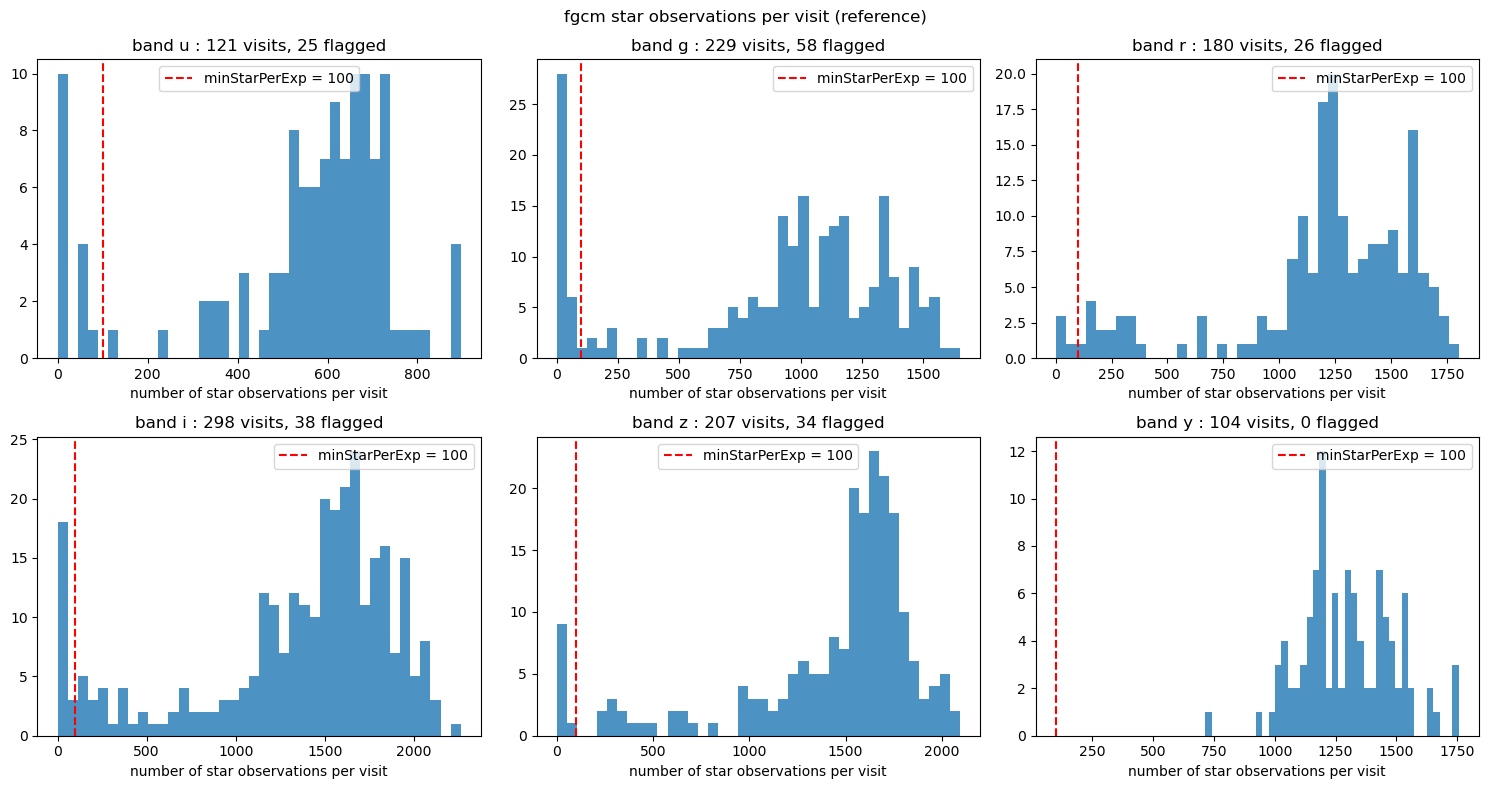

In [18]:
bands = [b for b in 'ugrizy' if b in set(visits['band'])]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=False)
for ax, band in zip(axes.ravel(), bands):
    sel = visits[visits['band'] == band]
    ax.hist(sel['n_obs'], bins=40, color='C0', alpha=0.8)
    ax.axvline(min_star, color='r', ls='--', label=f'minStarPerExp = {min_star}')
    ax.set_title(f'band {band} : {len(sel)} visits, {int(sel["flagged"].sum())} flagged')
    ax.set_xlabel('number of star observations per visit')
    ax.legend()
for ax in axes.ravel()[len(bands):]:
    ax.axis('off')
fig.suptitle(f'fgcm star observations per visit ({INSPECT})')
fig.tight_layout()
save_fig(fig, f'n_obs_per_visit_{INSPECT}')
plt.show()

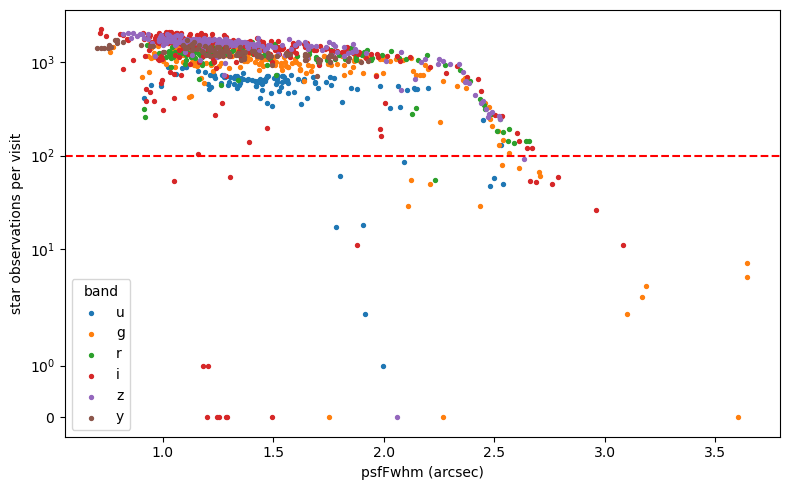

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
for band in bands:
    sel = visits[visits['band'] == band]
    ax.scatter(sel['psfFwhm'], sel['n_obs'], s=8, label=band)
ax.set_yscale('symlog')
ax.axhline(min_star, color='r', ls='--')
ax.set_xlabel('psfFwhm (arcsec)')
ax.set_ylabel('star observations per visit')
ax.legend(title='band')
fig.tight_layout()
save_fig(fig, f'n_obs_vs_fwhm_{INSPECT}')
plt.show()

## 8. Fit parameters and zeropoints

The fit outputs are found by name in the output table of section 6. The exact content of the catalogs is explored generically : fields, shapes, then a plot of every array whose name contains `Pwv`, `Tau`, `O3`, `Alpha` or `QeSys` (these are the atmosphere and instrument parameters that `fgcmFitCycle` fits). Check the field names in the printed list and adapt the selection below.

In [20]:
fit_names = [n for n in outputs_table.index if 'FitParameters' in n]
print('fit parameter datasets :', fit_names)

fit_catalogs = {}
for name in fit_names:
    refs = query_refs(name, INSPECT_COLLECTION)
    if refs:
        fit_catalogs[name] = butler.get(refs[0])
        print(f'===== {name}')
        summarize(fit_catalogs[name])

fit parameter datasets : ['fgcm_Cycle0_FitParameters', 'fgcm_Cycle1_FitParameters', 'fgcm_Cycle2_FitParameters', 'fgcm_Cycle3_FitParameters', 'fgcm_Cycle4_FitParameters', 'fgcm_Cycle5_FitParameters']


In [21]:
KEYS = ('pwv', 'tau', 'o3', 'alpha', 'qesys')
for name, cat in fit_catalogs.items():
    names = [n for n in cat.schema.getNames() if any(k in n.lower() for k in KEYS)]
    values = {}
    for n in names:
        try:
            arr = np.asarray(cat[n], dtype=float).ravel()
        except Exception:
            continue
        if arr.size > 1:
            values[n] = arr
    if not values:
        print(f'{name} : no array field matches {KEYS}')
        continue
    ncols = 3
    nrows = int(np.ceil(len(values) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.2 * nrows), squeeze=False)
    for ax, (n, arr) in zip(axes.ravel(), values.items()):
        ax.plot(arr, '.-', ms=3)
        ax.set_title(f'{n} ({arr.size})', fontsize=9)
        ax.set_xlabel('index')
    for ax in axes.ravel()[len(values):]:
        ax.axis('off')
    fig.suptitle(name)
    fig.tight_layout()
    save_fig(fig, f'{name}_{INSPECT}')
    plt.show()

In [22]:
def zeropoints(collection, max_visits=None):
    '''Per (visit, detector) zero point of fgcmPhotoCalibCatalog : zp = 31.4 - 2.5 log10(calibrationMean).

    mag_AB = zp - 2.5 log10(ADU) because the calibration mean is in nJy per ADU.
    '''
    refs = query_refs('fgcmPhotoCalibCatalog', collection)
    rows = []
    for ref in refs[:max_visits]:
        cat = butler.get(ref)
        for rec in cat:
            photo_calib = rec.getPhotoCalib()
            if photo_calib is None:
                continue
            rows.append(dict(visit=ref.dataId['visit'], detector=rec.getId(),
                             calib_mean=photo_calib.getCalibrationMean()))
    df = pd.DataFrame(rows)
    if len(df):
        df['zp'] = np.where(df['calib_mean'] > 0, 31.4 - 2.5 * np.log10(df['calib_mean']), np.nan)
    return df


MAX_VISITS = None      # e.g. 100 to go faster
zp = zeropoints(INSPECT_COLLECTION, MAX_VISITS)
print(len(zp), 'zero points,', zp['visit'].nunique() if len(zp) else 0, 'visits')
display(zp.head())
if len(zp):
    zp.to_csv(DATA_DIR / f'zeropoints_{INSPECT}.csv', index=False)

0 zero points, 0 visits


""


In [23]:
if len(zp):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].hist(zp['zp'].dropna(), bins=100)
    axes[0].set_xlabel('zero point (mag AB per ADU)')
    axes[0].set_ylabel('number of (visit, detector)')
    per_visit = zp.groupby('visit')['zp'].median()
    axes[1].plot(per_visit.index.astype(str), per_visit.values, '.', ms=3)
    axes[1].set_xlabel('visit (sorted)')
    axes[1].set_ylabel('median zero point over detectors')
    axes[1].set_xticks([])
    fig.tight_layout()
    save_fig(fig, f'zeropoints_{INSPECT}')
    plt.show()

## 9. Comparison with the bps run (`stage2_v2`)

When `EXECUTE = True` and the run is finished, set `INSPECT = 'new'` in section 1, rerun the notebook (or only the cells above) and then this section : the zero points of the new run are compared with the ones of the bps run. With identical inputs and configuration the two must agree (up to the random seed and the reserved stars of fgcm) : this is the check to pass before changing the look-up table.

In [24]:
if EXECUTE or INSPECT == 'new':
    zp_ref = zeropoints(STAGE2_REF, MAX_VISITS)
    zp_new = zeropoints(OUT_COLLECTION, MAX_VISITS)
    both = zp_ref.merge(zp_new, on=['visit', 'detector'], suffixes=('_ref', '_new'))
    both['dzp_mmag'] = 1000 * (both['zp_new'] - both['zp_ref'])
    print(len(zp_ref), 'reference,', len(zp_new), 'new,', len(both), 'in common')

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(both['zp_ref'], both['zp_new'], '.', ms=2)
    axes[0].set_xlabel('zero point, bps run')
    axes[0].set_ylabel('zero point, this notebook')
    axes[1].hist(both['dzp_mmag'].dropna(), bins=100)
    axes[1].set_xlabel('new - reference (mmag)')
    fig.tight_layout()
    save_fig(fig, 'zeropoints_new_vs_reference')
    plt.show()
    print('median, std of the difference (mmag) :', both['dzp_mmag'].median(), both['dzp_mmag'].std())
else:
    print('Nothing to compare yet : run section 5 with EXECUTE = True, then INSPECT = "new"')

   fgcmPhotoCalibCatalog: query failed (MissingCollectionError: No collection with name 'u/dagoret/LSSTCam/runelaiss1_20261111_tract2877patchsel_mediumpatcharray/fgcm_nb01_oneepoch' found.)


KeyError: 'visit'

## 10. Next steps : injecting the atmosphere

1. **Replay without change** (this notebook) : check that the new run reproduces `stage2_v2`.
2. **Look-up table** : `fgcmLookUpTable` is made by `FgcmMakeLutTask` from an atmosphere table (config `atmosphereTableName`; without it, fgcm calls MODTRAN4 itself). The table is a FITS file written by `fgcm.FgcmAtmosphereTable.saveTable` : a `PARS` table (grids `PMB`, `LNPWV`, `O3`, `LNTAU`, `ALPHA`, `SECZENITH`, standard values `*STD`, `ATMLAMBDA`, `ATMSTDTRANS`) and 4 images `PWVATM` (pwv x zenith x lambda), `O3ATM` (o3 x zenith x lambda), `O2ATM` and `RAYATM` (zenith x lambda). libRadtran must fill these arrays on the same grids (the ones shipped with fgcm are in `fgcm/data/tables/fgcm_atm_lsst*.fits`). Then put the new look-up table in a user collection chained *before* `LSSTCam/defaults`.
3. **What is fitted** : the atmosphere is parameterized *per night* : `parO3`, `parAlpha`, `parLnTauIntercept` / `parLnTauSlope`, `parLnPwvIntercept` / `parLnPwvSlope` / `parLnPwvQuadratic` (see the `fgcm_Cycle*_FitParameters` catalogs of section 8). `freezeStdAtmosphere=True` sets the bounds of all of them equal to their *current value* (code of `fgcmParameters`), but in a non-final cycle `resetAtmosphereParameters()` first overwrites them with the standard values, so editing a catalog does not work there (see notebook 02). Only the final cycle (`isFinalCycle=True`, no fit, no reset) uses the catalog values as they are. `fgcmcal` does not pass the fgcm `pwvFile` option (external PWV) and `externalTau` is not implemented in fgcm.
4. **Instrumental effects** : the remaining free parameters (`instrumentParsPerBand`, super-star flat, per-CCD gray, ...) are in the configuration printed in section 2.